In [1]:
!pip install -U datasets transformers evaluate accelerate tdqm gradio

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.9/323.9 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.2 MB/s eta 0:00:00
   

Paper: https://arxiv.org/pdf/2104.08821

### Simple contrastive learning of sentence embeddings
---

SimCSE, a simple contrastive learning framework that greatly advances state-of-the-art **sentence embeddings**.

It follows an **unsupervised approach**, which **takes an input sentence and predicts itself in a contrastive objective**, with only standard **dropout used as noise**. **dropout** acts as minimal data augmentation, and removing it leads to a representation collapse.

Note in paper, they also have supervised approach where they use NLI datasets like MNLI, SNLI. Used entailment sentences as postive pairs and contradiction sentence as hard negative and all other sentences in the batch as negatives.

In other words, we pass the same sentence to the pre-trained
encoder twice: by applying the standard dropout
twice, we can obtain two different embeddings as
“positive pairs”. Then we take other sentences in
the same mini-batch as “negatives”, and the model
predicts the positive one among the negatives.

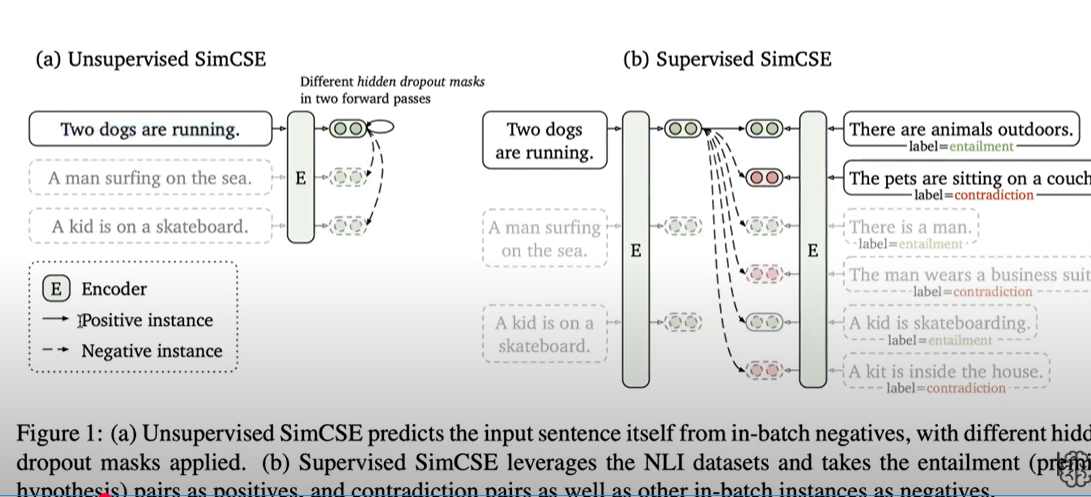

Contrastive learning aims to learn effective representation by pulling semantically close neighbors
together and pushing apart non-neighbors.

COntrastive Learning take a cross-entropy objective with in-batch negatives.

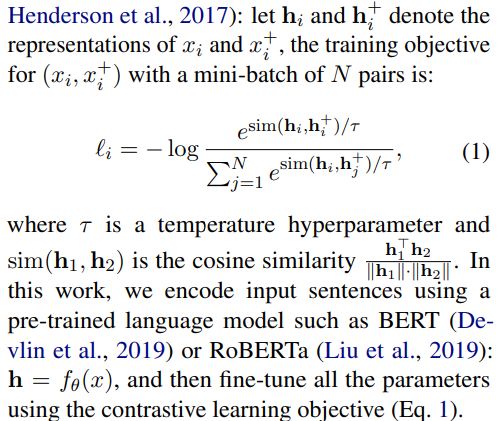

In [6]:
import datasets
from datasets import load_dataset, DatasetDict
import transformers

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from huggingface_hub import HfApi, create_repo, upload_folder, get_full_repo_name
from google.colab import userdata

import numpy as np
import pandas as pd
import scipy
from scipy.spatial.distance import cosine

import os, random, math, time


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

In [33]:
from datasets import load_dataset

raw_ds = load_dataset("glue", "mnli" )   # "princeton-nlp/datasets-for-simcse"
raw_ds

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9847
    })
})

In [34]:
from datasets import DatasetDict

def prepare_format(batch):
    combined = batch["premise"] + batch["hypothesis"]
    return {"text": combined}

def prepare_unsup_dataset(raw_dataset_dict):
    processed_splits = {}
    for split, ds in raw_dataset_dict.items():
        new_ds = ds.map(
            prepare_format,
            batched=True,
            remove_columns=ds.column_names,
            batch_size=1000  # adjustable
        )
        processed_splits[split] = new_ds
    return DatasetDict(processed_splits)

ds = prepare_unsup_dataset(raw_ds)

Map:   0%|          | 0/392702 [00:00<?, ? examples/s]

Map:   0%|          | 0/9815 [00:00<?, ? examples/s]

Map:   0%|          | 0/9832 [00:00<?, ? examples/s]

Map:   0%|          | 0/9796 [00:00<?, ? examples/s]

Map:   0%|          | 0/9847 [00:00<?, ? examples/s]

In [35]:
ds

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 785404
    })
    validation_matched: Dataset({
        features: ['text'],
        num_rows: 19630
    })
    validation_mismatched: Dataset({
        features: ['text'],
        num_rows: 19664
    })
    test_matched: Dataset({
        features: ['text'],
        num_rows: 19592
    })
    test_mismatched: Dataset({
        features: ['text'],
        num_rows: 19694
    })
})

In [38]:
ds["train"][1]["text"] # list(sentences)

'you know during the season and i guess at at your level uh you lose them to the next level if if they decide to recall the the parent team the Braves decide to call to recall a guy from triple A then a double A guy goes up to replace him and a single A guy goes up to replace him'

**Does SimCSE Use a Single Sentence or Multiple Sentences per Example?**

By Design:

Each item in the text column should be a single coherent input, but it can be a full sentence, a phrase, or multiple sentences — just like any natural input to a sentence encoder.

So, Yes, each text can contain multiple sentences.

SimCSE doesn't impose a constraint that each example must be a single sentence.

What matters is that:

- The same input text is passed twice through the model (with dropout).
- The model encodes it into an embedding.
- The dropout noise acts as augmentation in the unsupervised setting.

Whether it's a single sentence or multiple, the model will encode it based on how the tokenizer breaks it into tokens.

In [41]:
def prepare_targets(examples):
    processed = {}
    processed["source_text"] = examples["text"]
    processed["target_text"] = examples["text"]
    return processed

final_ds = DatasetDict({split: ds[split].map(prepare_targets, batched=True, remove_columns=ds[split].column_names) for split in ds.keys()})

Map:   0%|          | 0/785404 [00:00<?, ? examples/s]

Map:   0%|          | 0/19630 [00:00<?, ? examples/s]

Map:   0%|          | 0/19664 [00:00<?, ? examples/s]

Map:   0%|          | 0/19592 [00:00<?, ? examples/s]

Map:   0%|          | 0/19694 [00:00<?, ? examples/s]

In [42]:
final_ds

DatasetDict({
    train: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 785404
    })
    validation_matched: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 19630
    })
    validation_mismatched: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 19664
    })
    test_matched: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 19592
    })
    test_mismatched: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 19694
    })
})

In [53]:
train_ds = final_ds["train"].shuffle(seed=1234).select(range(10000))
val_ds = final_ds["validation_mismatched"].shuffle(seed=1234).select(range(1000))
test_ds = final_ds["test_mismatched"].shuffle(seed=1234).select(range(100))

simcse_ds = DatasetDict({"train": train_ds, "val": val_ds, "test": test_ds})

In [54]:
simcse_ds

DatasetDict({
    train: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 10000
    })
    val: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['source_text', 'target_text'],
        num_rows: 100
    })
})

In [47]:
train_ds[0]["source_text"], train_ds[0]["target_text"]

('Also on the grounds is the Matsugaoka Bunko, a research library established in memory of D.T.',
 'Also on the grounds is the Matsugaoka Bunko, a research library established in memory of D.T.')

### Prepreocess: Tokenizer

In [49]:
from transformers import AutoTokenizer

checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
tokenizer

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizerFast(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

In [60]:
max_seq_length = 128

def preprocess(examples):
    inputs = tokenizer(examples["source_text"], truncation=True, max_length=max_seq_length, padding="max_length") # separate tokenization
    targets = tokenizer(examples["target_text"], truncation=True, max_length=max_seq_length, padding="max_length") # separate tokenization
    return {
        "source_input_ids": inputs["input_ids"],
        "source_attn_mask": inputs["attention_mask"],
        "target_input_ids": targets["input_ids"],
        "target_attn_mask": targets["attention_mask"]
    }

In [61]:
tokenized_ds = simcse_ds.map(preprocess, batched=True, remove_columns=simcse_ds["train"].column_names)

tokenized_ds.set_format("torch")

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

In [62]:
tokenized_ds

DatasetDict({
    train: Dataset({
        features: ['source_input_ids', 'source_attn_mask', 'target_input_ids', 'target_attn_mask'],
        num_rows: 10000
    })
    val: Dataset({
        features: ['source_input_ids', 'source_attn_mask', 'target_input_ids', 'target_attn_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['source_input_ids', 'source_attn_mask', 'target_input_ids', 'target_attn_mask'],
        num_rows: 100
    })
})

### DataLoader

In [63]:
from transformers import default_data_collator
from torch.utils.data import DataLoader

train_dl = DataLoader(tokenized_ds["train"], batch_size=32, shuffle=True, collate_fn=default_data_collator)
eval_dl = DataLoader(tokenized_ds["val"], batch_size=32, collate_fn=default_data_collator)

In [69]:
for batch in train_dl:
    break

print([(kw, batch[kw].shape) for kw in batch.keys()])

[('source_input_ids', torch.Size([32, 128])), ('source_attn_mask', torch.Size([32, 128])), ('target_input_ids', torch.Size([32, 128])), ('target_attn_mask', torch.Size([32, 128]))]


In [75]:
batch

(0,
 {'source_input_ids': tensor([[  101,  1996,  2434,  ...,     0,     0,     0],
          [  101,  3398,  2008,  ...,     0,     0,     0],
          [  101,  3016,  6856,  ...,     0,     0,     0],
          ...,
          [  101,  5211, 12992,  ...,     0,     0,     0],
          [  101,  1045,  7427,  ...,     0,     0,     0],
          [  101,  2009,  4472,  ...,     0,     0,     0]]),
  'source_attn_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
          [1, 1, 1,  ..., 0, 0, 0],
          [1, 1, 1,  ..., 0, 0, 0],
          ...,
          [1, 1, 1,  ..., 0, 0, 0],
          [1, 1, 1,  ..., 0, 0, 0],
          [1, 1, 1,  ..., 0, 0, 0]]),
  'target_input_ids': tensor([[  101,  1996,  2434,  ...,     0,     0,     0],
          [  101,  3398,  2008,  ...,     0,     0,     0],
          [  101,  3016,  6856,  ...,     0,     0,     0],
          ...,
          [  101,  5211, 12992,  ...,     0,     0,     0],
          [  101,  1045,  7427,  ...,     0,     0,     0],
          [

### Model

In [51]:
from transformers import AutoModel, AutoConfig

checkpoint = "bert-base-uncased"

config = AutoConfig.from_pretrained(checkpoint)
model = AutoModel.from_pretrained(checkpoint)
model.to(device)

model  # observe the model has no head.. we have final layer that outputs the hidden representation

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

### Mean Pooler

SBERT adds a pooling operation to the output of BERT / RoBERTa to derive a fixed size sentence embedding from token level embeddings.

## What is Pooling in Transformers?

Transformers output **token-level embeddings**, i.e., for each word (token) in the input. But if you want a **single fixed-size vector for the entire sentence**, you need to **pool** the token embeddings into one.

> **Pooling = combining all token embeddings into one sentence embedding**

---

## Why Use Different Pooling Methods?

Different tasks or objectives can benefit from different pooling strategies:

| Task                               | Pooling Strategy |
| ---------------------------------- | ---------------- |
| Semantic similarity / retrieval    | Mean or CLS      |
| Classification                     | CLS              |
| General-purpose sentence embedding | Mean / Max       |

---

## 1. **\[CLS] Token Pooling**

### What:

Use the embedding of the special `[CLS]` token as the sentence representation.

### Why:

The `[CLS]` token is designed to capture a summary of the sentence — especially when fine-tuned for tasks like classification.

### Catch:

* Only works well if the model was **trained with \[CLS] as representation**, e.g., fine-tuned for classification.
* May perform poorly on unsupervised tasks (like SimCSE without supervision).

```python
cls_embedding = token_embeddings[:, 0, :]  # shape: (batch_size, hidden_dim)
```

---

## 2. **Mean Pooling**

### What:

Take the mean (average) of all token embeddings **excluding padding**.

### Why:

* Simple and stable.
* Works well for unsupervised sentence embeddings (like SimCSE or Sentence-BERT).
* Doesn't rely on \[CLS].

```python
mean_pool = (token_embeds * mask).sum(1) / mask.sum(1)
```

---

## 3. **Max Pooling**

### What:

Take the maximum value (per dimension) across all token embeddings.

### Why:

* Captures the most "activated" features across the sentence.
* Useful when certain keywords dominate the sentence semantics.

```python
masked_embeddings = token_embeds.masked_fill(mask == 0, -1e9)
max_pool = masked_embeddings.max(1).values
```

---

## 4. **Mean-Max Pooling (Concat)**

### What:

Concatenate both mean and max pooled embeddings:

```python
sentence_vector = torch.cat([mean_pool, max_pool], dim=-1)
```

### Why:

* Combines global averaging and prominent features.
* Often used in Sentence-BERT variants.

---

## 5. **Sentence-Transformers Pooling**

`sentence-transformers` library provides configurable pooling:

* `pooling_mode_cls_token=True`
* `pooling_mode_mean_tokens=True`
* `pooling_mode_max_tokens=True`

This lets you define combinations (e.g., mean+max).

---

## Which One to Use?

| Scenario                           | Recommended Pooling |
| ---------------------------------- | ------------------- |
| Classification                     | `[CLS]`             |
| Semantic Similarity (unsupervised) | `Mean`              |
| Sentence Embeddings (general)      | `Mean` / `Mean+Max` |
| Keyword Matching                   | `Max`               |

---

## SimCSE-Specific

* **Unsupervised SimCSE** → Uses `[CLS]` representation from BERT without fine-tuning.
* **Supervised SimCSE** → Also relies on `[CLS]`, but model is fine-tuned with contrastive loss to make CLS useful.

However, many researchers have found **mean pooling gives better transfer** to downstream tasks.

---

## Summary

| Pooling  | How it Works                     | Pros                    | Cons                          |
| -------- | -------------------------------- | ----------------------- | ----------------------------- |
| CLS      | Use `[CLS]` token embedding      | Compact, fast           | Not great without fine-tuning |
| Mean     | Average all non-padding tokens   | Stable, general-purpose | May dilute strong features    |
| Max      | Take max per embedding dimension | Focus on strong signals | Can ignore context            |
| Mean+Max | Combine mean and max             | Best of both worlds     | Double-sized vector           |

---



In [70]:
def mean_pool(token_embeds, attention_mask):
    # attention_mask: (bs, seq_len)
    # token_embeds: (bs, seq_len, hidden_dim)
    in_mask = attention_mask.unsqueeze(-1).float()  # (bs, seq_len, 1)
    summed = torch.sum(token_embeds * in_mask, dim=1)  # (bs, hidden_dim)
    counted = torch.clamp(in_mask.sum(dim=1), min=1e-9)  # (bs, 1)
    mean_pooled = summed / counted  # (bs, hidden_dim)
    return mean_pooled

The goal is to compute a mean pooling over the token embeddings, but only over the non-padding tokens, using the attention_mask.

This is a very common approach for sentence embeddings from token-level models like BERT.



### Loss - constrative loss (NT-Xent / InfoNCE)

In [71]:
import torch
import torch.nn.functional as F

def contrastive_loss(h_z, h_z_prime, temperature=1.0):
    # h_z: (bs, hidden_dim) - pooled output embeddings of the source text
    # h_z_prime: (bs, hidden_dim) - pooled output embeddings of the target texts
    # Ensures all vectors are unit-length (L2 norm = 1), so their dot product is equal to cosine similarity
    h_z = F.normalize(h_z, p=2, dim=-1)
    h_z_prime = F.normalize(h_z_prime, p=2, dim=-1)
    sim_matrix = torch.matmul(h_z, h_z_prime.T) / temperature # (bs, bs) Each row i contains the cosine similarities between h_z[i] and all h_z_prime[j] in the batch.
    # The diagonal entries (i = j) of sim_matrix are the positive pairs (correct matches)
    labels = torch.arange(h_z.size(0)).to(h_z.device)
    return F.cross_entropy(sim_matrix, labels)

```
labels = torch.arange(h_z.size(0)).to(h_z.device)
```

Creates a vector: [0, 1, 2, ..., B-1]

Why?

Because we want the model to correctly identify that:

For row i in sim_matrix, the i-th column is the correct (positive) match.

So this tells CrossEntropyLoss that for sim_matrix[i], the true label is i.

In other words:
```
sim_matrix[i] → logits for candidate matches for h_z[i]
labels[i] = i → correct match is at position i
```

labels = [0, 1, 2, ..., B-1] means:

→ For input i, the correct positive match is at position i in the row.

The model is penalized if the highest similarity is not at the correct index.

This is why this works for contrastive learning: it teaches the model to pull together positive pairs and push apart all others.

Let’s say batch size B = 4. Then:

labels = [0, 1, 2, 3]

sim_matrix.shape = (4, 4)

Each row contains scores of h_z[i] compared with all h_z_prime[j].

For example:

sim_matrix[1] = [sim(h1, h1′), sim(h1, h2′), sim(h1, h3′), sim(h1, h4′)]

Label is 1 → correct match is h1′





In our case:

* We are not **duplicating a sentence** with dropout.(duplication done in paper)
* Instead, each **source sentence** is paired with a corresponding **target sentence** (like translation, paraphrase, question-answer, etc.).
* The **embedding of the source** should be close to the **embedding of its paired target**, and far from all other targets in the batch.

When you have **two different texts as input pairs** — such as a **source text** and a **target text** — the setup shifts from **SimCSE-style unsupervised contrastive learning** to something closer to a **supervised contrastive setting**, where each `(source, target)` pair is a **positive match**, and all others are treated as negatives.

---

### How is Contrastive Loss Computed in our case?

Let’s say:

* You have `N` source-target pairs.
* Let `emb_src` be the embeddings of all source sentences.
* Let `emb_tgt` be the embeddings of all target sentences.

Then:

* You compute cosine similarity between every source and all targets: `sim(i, j)` → similarity between source `i` and target `j`.
* For each source `i`, the **positive** is the matching target `i`, and all other targets are **negatives**.
* You use a **cross-entropy loss**, treating the correct target index as the label.

---


This encourages the model to:

* **Align** semantically related source-target embeddings.
* **Separate** unrelated pairs in the embedding space.

---

### 🧩 Use Cases

* Parallel corpora (e.g., translation: English → German)
* Sentence similarity (e.g., question → paraphrase)
* Retrieval (e.g., query → document)



**contrastive loss function** suitable for **unsupervised SimCSE-style training** after you have your batch of sentence embeddings without distinction of source and target text.

---

### Assumptions

* You have a batch of `N` **sentence embeddings**, where each input sentence was **duplicated once** (so batch size is `2N`).
* The model sees each sentence **twice with different dropout masks**, e.g., `["a", "a", "b", "b", ..., "n", "n"]`.
* You're using **in-batch negatives**.
* The positive pair for every `i` is at `(i+1)` if `i` is even, and `(i-1)` if `i` is odd.

---

### Contrastive Loss (NT-Xent / InfoNCE)

```python
import torch
import torch.nn.functional as F

def simcse_unsup_loss(embeddings, temperature=0.05):
    """
    embeddings: Tensor of shape (2N, hidden_size), where each sentence appears twice.
    temperature: Scaling factor for contrastive loss.
    """
    # Normalize embeddings
    embeddings = F.normalize(embeddings, p=2, dim=1)  # (2N, hidden)

    # Compute cosine similarity matrix
    similarity_matrix = torch.matmul(embeddings, embeddings.T)  # (2N, 2N)

    # Remove similarity with self
    mask = torch.eye(similarity_matrix.size(0), dtype=torch.bool).to(embeddings.device)
    similarity_matrix.masked_fill_(mask, -1e12)

    # Scale by temperature
    similarity_matrix /= temperature

    # Create labels: each i's positive pair is (i+1) if even, (i-1) if odd
    batch_size = embeddings.size(0)
    labels = torch.arange(0, batch_size, device=embeddings.device)
    labels = labels + 1 - 2 * (labels % 2)

    # Compute cross-entropy loss
    loss = F.cross_entropy(similarity_matrix, labels)
    return loss
```

---

### Explanation

* `F.normalize(...)`: Ensures cosine similarity behaves properly.
* `torch.matmul(...)`: Gives us a cosine similarity matrix.
* `labels`: Pairs each example with its duplicate (positive pair).
* `cross_entropy`: Treats all other entries as negatives.

---

### Example Use

```python
with torch.no_grad():
    model.eval()
    embeddings = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).last_hidden_state
    pooled = mean_pool(embeddings, batch["attention_mask"])

loss = simcse_unsup_loss(pooled)
```

In SimCSE-style unsupervised contrastive learning, each input sentence is duplicated to form a positive pair—typically using two different dropout masks during encoding. The contrastive loss relies on knowing which two embeddings form a positive pair, and in the standard setup, this is done by keeping each pair adjacent in the batch (e.g., sentence A at positions 0 and 1, sentence B at 2 and 3, etc.). This predictable ordering allows the loss function to assume that the positive for index `i` is simply `i+1` (if `i` is even) or `i-1` (if `i` is odd). However, if the batch is shuffled, this assumption breaks down, and the model no longer knows which embedding is the correct positive for each anchor. In that case, you must explicitly track the position of each positive pair using an index mapping, because the model needs that information to properly contrast positives against in-batch negatives. Therefore, unless such a mapping is managed carefully, it's best not to shuffle the batch when using this type of loss.



### Optimizer and Scheduler

In [73]:
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW

# Optimizer
no_decay = ["bias", "LayerNorm.weight"]
weight_decay = 0.01
params_wo_decay = []
params_with_decay = []
for name, p in model.named_parameters():
    if any(nd in name for nd in no_decay):
        params_wo_decay.append(p)
    else:
        params_with_decay.append(p)

grouped_parameters = [
    {"params": params_with_decay, "weight_decay": weight_decay},
    {"params": params_wo_decay, "weight_decay": 0.0}
]

optimizer = AdamW(grouped_parameters, lr=1e-5, eps=1e-8)

# Scheduler
num_epochs = 5
gradient_accumulation_steps = 8
warmup_proportion = 0.1
num_training_steps = (num_epochs * len(train_dl)) // gradient_accumulation_steps
num_warmup_steps = int(warmup_proportion * num_training_steps)

scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=num_warmup_steps, num_training_steps=num_training_steps)

### Training

In [ ]:
from tqdm.auto import tqdm

for epoch in range(num_epochs):
    model.train()
    for batch in enumerate(tqdm(train_dl, leave=True)):
        optimizer.zero_grad()
        batch = {k: v.to(device) for k, v in batch[1].items()}
        u = model(batch["source_input_ids"], attention_mask=batch["source_attn_mask"])
        v = model(batch["target_input_ids"], attention_mask=batch["target_attn_mask"])

        u_last_hidden_state = u.last_hidden_state # bs, seq_len, hidden_dim
        v_last_hidden_state = v.last_hidden_state # bs, seq_len, hidden_dim

        # mean pooling
        u_mean_pool = mean_pool(u_last_hidden_state, batch["source_attn_mask"]) # bs, hidden_dim
        v_mean_pool = mean_pool(v_last_hidden_state, batch["target_attn_mask"]) # bs, hidden_dim

        # loss
        loss = contrastive_loss(u_mean_pool, v_mean_pool)
        loss.backward()
        optimizer.step()
        scheduler.step()

    print(f"Epoch: {epoch} | Loss: {loss.item():.3f}")

In [ ]:
total_similarity = 0

with torch.no_grad():
    for batch in enumerate(eval_dl):
        batch = {k: v.to(device) for k, v in batch[1].items()}
        u = model(batch["source_input_ids"], attention_mask=batch["source_attn_mask"])
        v = model(batch["target_input_ids"], attention_mask=batch["target_attn_mask"])

        u_last_hidden_state = u.last_hidden_state # bs, seq_len, hidden_dim
        v_last_hidden_state = v.last_hidden_state # bs, seq_len, hidden_dim

        # mean pooling
        u_mean_pool = mean_pool(u_last_hidden_state, batch["source_attn_mask"]) # bs, hidden_dim
        v_mean_pool = mean_pool(v_last_hidden_state, batch["target_attn_mask"]) # bs, hidden_dim

        sim_score = F.cosine_similarity(u_mean_pool, v_mean_pool).mean()
        total_similarity += sim_score

avg_similarity = total_similarity / len(eval_dl)
print(f"Average Cosine Similarity: {avg_similarity:.4f}")

### Inference

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

def calculate_similarity(model, tokenizer, sentence_a, sentence_b, device):
    inputs_a = tokenizer(sentence_a, return_tensors="pt", truncation=True, padding=True).to(device)
    inputs_b = tokenizer(sentence_b, return_tensors="pt", truncation=True, padding=True).to(device)

    input_ids_a = inputs_a["input_ids"]
    attn_a = inputs_a["attention_mask"]
    input_ids_b = inputs_b["input_ids"]
    attn_b = inputs_b["attention_mask"]
    with torch.no_grad():
        u = model(input_ids_a, attention_mask=attn_a)[0]
        v = model(input_ids_b, attention_mask=attn_b)[0]

    # mean pooling
    u = mean_pool(u, attn_a).detach().cpu().numpy().reshape(-1)
    v = mean_pool(u, attn_b).detach().cpu().numpy().reshape(-1)
    # calculate sim
    sim_score = cosine_similarity(u.reshape(1, -1), v.reshape(1, -1))[0, 0]
    return sim_score

In [ ]:
sentence_a = "Your contribution helped to make it possible"
sentence_b = "It is of great help with your contribution"
similarity = calculate_similarity(model, tokenizer, sentence_a, sentence_b, device)
print(f"Cosine Similarity: {similarity:.4f}")

In [ ]:
sentence_a = "Your contribution helped to make it possible"
sentence_b = "It is not of great help with your contribution"
similarity = calculate_similarity(model, tokenizer, sentence_a, sentence_b, device)
print(f"Cosine Similarity: {similarity:.4f}")